# TRENIRANJE RANDOM FOREST MODELA

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")

# Značajke i ciljna varijabla
features = ["insolacija", "naoblaka", "temperatura", "Peak Power (kW)"]
target = "PV Yield (kWh)"

# Ukloni redove s NaN vrijednostima
df = df[features + [target]].dropna()

# Odvoji ulazne i izlazne vrijednosti
X = df[features]
y = df[target]

# Standardizacija
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Podjela na train i test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [26]:
# Inicijalizacija i treniranje
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predikcija
y_pred = rf_model.predict(X_test)

In [27]:
# Evaluacija
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Evaluacija Random Forest modela:")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")

Evaluacija Random Forest modela:
MAE: 1.89
MSE: 8.08
R²: 0.92


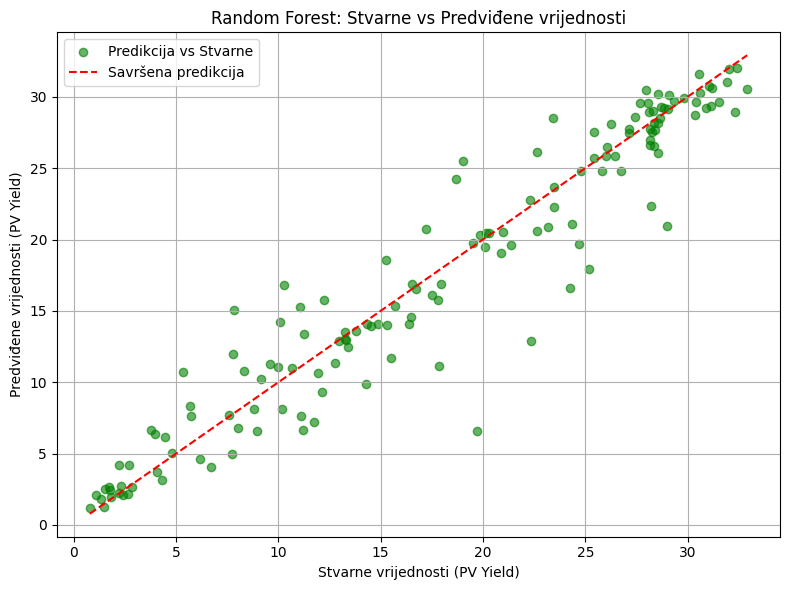

In [32]:
# Vizualizacija: scatter graf stvarnih vs. predviđenih vrijednosti
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='green', alpha=0.6, label='Predikcija vs Stvarne')

# Linija savršene predikcije
lims = [min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))]
plt.plot(lims, lims, 'r--', label='Savršena predikcija')

plt.xlabel("Stvarne vrijednosti (PV Yield)")
plt.ylabel("Predviđene vrijednosti (PV Yield)")
plt.title("Random Forest: Stvarne vs Predviđene vrijednosti")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grafovi/RFpredict.png")
plt.show()

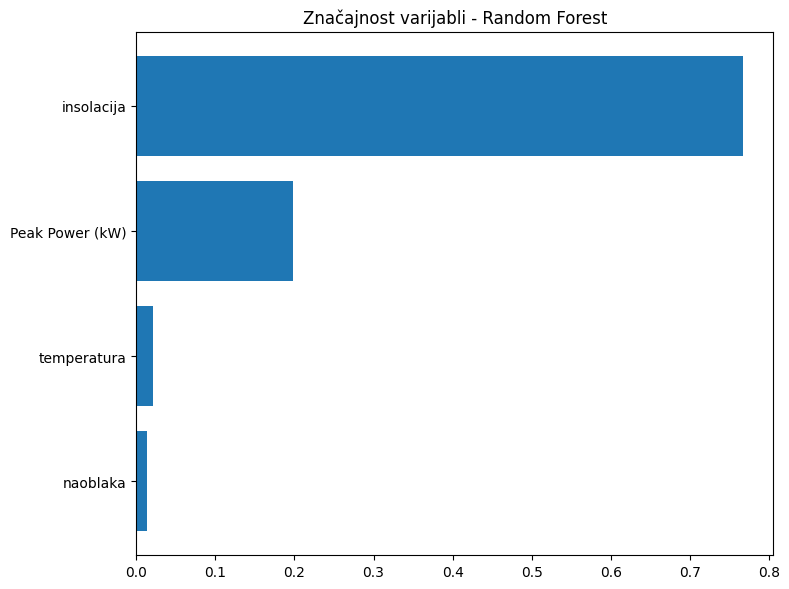

In [29]:
import numpy as np

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 6))
plt.title("Značajnost varijabli - Random Forest")
plt.barh(range(len(indices)), importances[indices], align="center")
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("grafovi/RF_feature_importance.png")
plt.show()

## FINE-TUNING RF MODELA

In [30]:
from sklearn.model_selection import GridSearchCV

# Definiranje mreže parametara za pretragu
param_grid = {
    'n_estimators': [120, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Inicijalizacija Random Forest modela
rf = RandomForestRegressor(random_state=42)

# GridSearch s 3-fold cross-validation
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid,
                           cv=3, scoring='r2', verbose=1, n_jobs=-1)

# Treniranje
grid_search.fit(X_train, y_train)

# Prikaz najboljih hiperparametara
print("Najbolji parametri:", grid_search.best_params_)

# Uzimanje najboljeg modela
best_rf_model = grid_search.best_estimator_

# Predikcija s najboljim modelom
y_pred_best = best_rf_model.predict(X_test)

# Evaluacija
mae_best = mean_absolute_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
r2_best = r2_score(y_test, y_pred_best)

print("Evaluacija najboljeg Random Forest modela:")
print(f"MAE: {mae_best:.2f}")
print(f"MSE: {mse_best:.2f}")
print(f"R²: {r2_best:.2f}")

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Najbolji parametri: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Evaluacija najboljeg Random Forest modela:
MAE: 1.90
MSE: 8.17
R²: 0.91
